In [19]:
# 1. Se placer à la racine du projet
%cd C:\Users\PC\App_Enedis

C:\Users\PC\App_Enedis


In [20]:
# 2. Vérifier le dossier courant
import os
print(os.getcwd())

C:\Users\PC\App_Enedis


In [21]:
# 3. Importer les bibliothèques
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

In [22]:
# 4. Charger les données nettoyées
df = pd.read_csv(
    "output/ademe_data_69_cleaned.csv",
    low_memory=False
)

In [23]:
# Afficher la taille du DataFrame :
# nombre de lignes et nombre de colonnes
print("Dimensions du DataFrame :", df.shape)


# Vérifier que la colonne cible existe bien.
# Cette colonne correspond à l'étiquette DPE à prédire : A, B, C, D, E, F ou G.
print("\nColonne cible présente :")
print("etiquette_dpe" in df.columns)


# Liste des variables que nous voulons utiliser pour entraîner le modèle.
colonnes_utiles = [
    "cout_total_5_usages",
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "age_batiment",
    "altitude_moyenne",
    "type_energie_principale_chauffage",
    "type_batiment",
    "zone_climatique",
    "etiquette_dpe"
]


# Vérifier une par une si toutes les variables nécessaires
# sont présentes dans le DataFrame.
print("\nVariables disponibles :")

for col in colonnes_utiles:
    print(col, "->", col in df.columns)

Dimensions du DataFrame : (13481, 37)

Colonne cible présente :
True

Variables disponibles :
cout_total_5_usages -> True
surface_habitable_logement -> True
nombre_niveau_logement -> True
age_batiment -> True
altitude_moyenne -> True
type_energie_principale_chauffage -> True
type_batiment -> True
zone_climatique -> True
etiquette_dpe -> True


In [24]:
# Variables quantitatives :
# ce sont les variables numériques utilisées pour expliquer la classe DPE.
quantitative_features = [
    "cout_total_5_usages",
    "surface_habitable_logement",
    "nombre_niveau_logement",
    "age_batiment",
    "altitude_moyenne"
]


# Variables qualitatives :
# ce sont les variables catégorielles qui devront être encodées avant
# d'être utilisées par les modèles de Machine Learning.
qualitative_features = [
    "type_energie_principale_chauffage",
    "type_batiment",
    "zone_climatique"
]


# Variable cible :
# c'est la valeur que notre modèle doit apprendre à prédire.
target = "etiquette_dpe"


# X contient toutes les variables explicatives.
X = df[
    quantitative_features
    + qualitative_features
]


# y contient uniquement la classe DPE à prédire.
y = df[target]


# Afficher les dimensions pour vérifier que X et y
# contiennent bien le même nombre de logements.
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (13481, 8)
Dimensions de y : (13481,)


In [25]:
# Compter les valeurs manquantes pour chacune des variables explicatives.
print("Valeurs manquantes dans X :")
print(X.isna().sum())


# Compter les valeurs manquantes dans la variable cible.
print("\nValeurs manquantes dans y :")
print(y.isna().sum())

Valeurs manquantes dans X :
cout_total_5_usages                  0
surface_habitable_logement           0
nombre_niveau_logement               0
age_batiment                         0
altitude_moyenne                     0
type_energie_principale_chauffage    0
type_batiment                        0
zone_climatique                      0
dtype: int64

Valeurs manquantes dans y :
0


In [26]:
# Compter le nombre de logements pour chaque classe DPE.
# Cela permet de vérifier si les classes A, B, C, D, E, F et G
# sont représentées de manière équilibrée dans le dataset.
repartition_classes = y.value_counts().sort_index()

print("Répartition des classes DPE :")
print(repartition_classes)


# Calculer également la proportion de chaque classe en pourcentage.
# normalize=True transforme les effectifs en proportions.
repartition_pourcentage = (
    y.value_counts(normalize=True)
    .sort_index()
    * 100
)

print("\nRépartition en pourcentage :")
print(repartition_pourcentage.round(2))

Répartition des classes DPE :
etiquette_dpe
A    1181
B    1725
C    7213
D    2068
E     902
F     240
G     152
Name: count, dtype: int64

Répartition en pourcentage :
etiquette_dpe
A     8.76
B    12.80
C    53.50
D    15.34
E     6.69
F     1.78
G     1.13
Name: proportion, dtype: float64


In [27]:
# Importer la fonction qui permet de séparer les données
# en jeu d'entraînement et jeu de test.
from sklearn.model_selection import train_test_split


# Séparer les données :
# - 70 % pour entraîner le modèle
# - 30 % pour tester ses performances
#
# stratify=y permet de conserver la même proportion
# de classes DPE (A, B, C, D, E, F, G)
# dans le train et dans le test.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


# Afficher les dimensions pour vérifier le découpage.
print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test  :", X_test.shape)
print("Dimensions y_train :", y_train.shape)
print("Dimensions y_test  :", y_test.shape)

Dimensions X_train : (9436, 8)
Dimensions X_test  : (4045, 8)
Dimensions y_train : (9436,)
Dimensions y_test  : (4045,)


In [28]:
# Vérifier la répartition des classes dans le jeu d'entraînement.
# On calcule ici le pourcentage de chaque classe DPE.
print("Répartition dans y_train :")

print(
    (
        y_train
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


# Vérifier la répartition des classes dans le jeu de test.
# Les proportions doivent être très proches de celles de y_train.
print("\nRépartition dans y_test :")

print(
    (
        y_test
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

Répartition dans y_train :
etiquette_dpe
A     8.76
B    12.79
C    53.51
D    15.35
E     6.69
F     1.78
G     1.12
Name: proportion, dtype: float64

Répartition dans y_test :
etiquette_dpe
A     8.75
B    12.81
C    53.50
D    15.33
E     6.70
F     1.78
G     1.14
Name: proportion, dtype: float64


In [29]:
# Importer les outils de prétraitement de scikit-learn.
# ColumnTransformer permet d'appliquer des transformations différentes
# selon le type de variable.
from sklearn.compose import ColumnTransformer

# StandardScaler standardise les variables numériques.
# OneHotEncoder transforme les catégories en colonnes numériques.
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Création du préprocesseur :
# - les variables quantitatives sont standardisées ;
# - les variables qualitatives sont encodées avec OneHotEncoder.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            quantitative_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            qualitative_features
        )
    ]
)


# Ajuster le préprocesseur uniquement sur les données d'entraînement.
# C'est important pour éviter une fuite d'information depuis le jeu de test.
preprocessor.fit(X_train)


# Transformer les jeux d'entraînement et de test.
X_train_prepared = preprocessor.transform(X_train)
X_test_prepared = preprocessor.transform(X_test)


# Afficher les dimensions obtenues après transformation.
print("Dimensions X_train après preprocessing :", X_train_prepared.shape)
print("Dimensions X_test après preprocessing  :", X_test_prepared.shape)

Dimensions X_train après preprocessing : (9436, 12)
Dimensions X_test après preprocessing  : (4045, 12)


In [30]:
# Importer plusieurs modèles de classification
# afin de comparer leurs performances sur le même jeu de données.
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Importer les métriques utilisées pour comparer les modèles.
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)


# Dictionnaire contenant les modèles à tester.
# class_weight="balanced" aide certains modèles à mieux prendre
# en compte les classes minoritaires comme F et G.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}


# Liste qui servira à stocker les résultats de chaque modèle.
results = []


# Entraîner et évaluer chaque modèle.
for name, model in models.items():

    print(f"Entraînement : {name}")

    # Entraîner le modèle sur les données préparées.
    model.fit(X_train_prepared, y_train)

    # Faire les prédictions sur le jeu de test.
    y_pred = model.predict(X_test_prepared)

    # Accuracy :
    # proportion globale de prédictions correctes.
    accuracy = accuracy_score(y_test, y_pred)

    # F1 macro :
    # calcule le F1-score de chaque classe puis fait la moyenne.
    # Toutes les classes ont le même poids, même F et G.
    f1_macro = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    # Recall macro :
    # mesure la capacité du modèle à retrouver les vraies classes.
    recall_macro = recall_score(
        y_test,
        y_pred,
        average="macro"
    )

    # Ajouter les résultats au tableau.
    results.append({
        "Modele": name,
        "Accuracy": accuracy,
        "F1_macro": f1_macro,
        "Recall_macro": recall_macro
    })


# Transformer les résultats en DataFrame pour faciliter la comparaison.
results_df = pd.DataFrame(results)


# Classer les modèles du meilleur au moins bon selon le F1 macro.
results_df.sort_values(
    "F1_macro",
    ascending=False
)

Entraînement : Logistic Regression
Entraînement : Random Forest
Entraînement : Decision Tree
Entraînement : KNN


,Modele,Accuracy,F1_macro,Recall_macro
1,Random Forest,0.815575,0.665765,0.636956
2,Decision Tree,0.781211,0.627885,0.627226
3,KNN,0.774784,0.615910,0.575502
0,Logistic Regression,0.609147,0.432896,0.486702


In [31]:
# Importer XGBoost pour tester un modèle de boosting.
from xgboost import XGBClassifier

# LabelEncoder transforme les classes DPE :
# A, B, C, D, E, F, G
# en valeurs numériques :
# 0, 1, 2, 3, 4, 5, 6
from sklearn.preprocessing import LabelEncoder

# compute_sample_weight permet de donner davantage de poids
# aux classes rares comme F et G pendant l'entraînement.
from sklearn.utils.class_weight import compute_sample_weight



# 1. Encoder les classes DPE


label_encoder = LabelEncoder()

# Le fit est réalisé sur y_train.
y_train_encoded = label_encoder.fit_transform(y_train)

# Pour y_test, on utilise exactement le même encodage.
y_test_encoded = label_encoder.transform(y_test)

print("Correspondance des classes :", label_encoder.classes_)

Correspondance des classes : ['A' 'B' 'C' 'D' 'E' 'F' 'G']


In [32]:
# ------------------------------------------------------------
# 2. Calculer les poids des observations
# ------------------------------------------------------------

# Les classes rares reçoivent automatiquement un poids plus important.
# Cela aide XGBoost à ne pas privilégier uniquement la classe C.
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)


# ------------------------------------------------------------
# 3. Créer le modèle XGBoost
# ------------------------------------------------------------

xgb_model = XGBClassifier(
    objective="multi:softprob",   # Classification multiclasse
    num_class=7,                  # 7 classes : A à G
    n_estimators=300,             # Nombre d'arbres
    max_depth=6,                  # Profondeur maximale des arbres
    learning_rate=0.05,           # Vitesse d'apprentissage
    subsample=0.8,                # Utilise 80 % des lignes par arbre
    colsample_bytree=0.8,         # Utilise 80 % des variables par arbre
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# 4. Entraîner XGBoost
# ------------------------------------------------------------

xgb_model.fit(
    X_train_prepared,
    y_train_encoded,
    sample_weight=sample_weights
)


# ------------------------------------------------------------
# 5. Faire les prédictions
# ------------------------------------------------------------

y_pred_xgb_encoded = xgb_model.predict(X_test_prepared)

# Reconvertir 0,1,2... en A,B,C...
y_pred_xgb = label_encoder.inverse_transform(
    y_pred_xgb_encoded
)


# ------------------------------------------------------------
# 6. Calculer les performances
# ------------------------------------------------------------

accuracy_xgb = accuracy_score(
    y_test,
    y_pred_xgb
)

f1_xgb = f1_score(
    y_test,
    y_pred_xgb,
    average="macro"
)

recall_xgb = recall_score(
    y_test,
    y_pred_xgb,
    average="macro"
)


print("XGBoost")
print("Accuracy :", round(accuracy_xgb, 4))
print("F1 macro :", round(f1_xgb, 4))
print("Recall macro :", round(recall_xgb, 4))

XGBoost
Accuracy : 0.7765
F1 macro : 0.6379
Recall macro : 0.6592


In [33]:
# Importer les outils permettant d'analyser les performances
# classe par classe.
from sklearn.metrics import classification_report, confusion_matrix


# Récupérer le modèle Random Forest déjà entraîné.
random_forest_model = models["Random Forest"]


# Faire les prédictions sur le jeu de test.
y_pred_rf = random_forest_model.predict(X_test_prepared)


# Afficher les performances détaillées pour chaque classe DPE.
# precision : parmi les prédictions d'une classe, combien sont correctes
# recall    : parmi les vraies valeurs d'une classe, combien sont retrouvées
# f1-score  : compromis entre precision et recall
print("Classification report - Random Forest")
print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=3
    )
)

Classification report - Random Forest
              precision    recall  f1-score   support

           A      0.913     0.921     0.917       354
           B      0.828     0.695     0.756       518
           C      0.870     0.929     0.899      2164
           D      0.658     0.684     0.671       620
           E      0.622     0.509     0.560       271
           F      0.452     0.264     0.333        72
           G      0.618     0.457     0.525        46

    accuracy                          0.816      4045
   macro avg      0.709     0.637     0.666      4045
weighted avg      0.809     0.816     0.810      4045



In [34]:
# Afficher les performances détaillées de XGBoost
# pour chaque classe DPE.
print("Classification report - XGBoost")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        digits=3
    )
)

Classification report - XGBoost
              precision    recall  f1-score   support

           A      0.904     0.935     0.919       354
           B      0.687     0.795     0.737       518
           C      0.931     0.813     0.868      2164
           D      0.590     0.715     0.646       620
           E      0.484     0.546     0.513       271
           F      0.314     0.375     0.342        72
           G      0.444     0.435     0.440        46

    accuracy                          0.777      4045
   macro avg      0.622     0.659     0.638      4045
weighted avg      0.798     0.777     0.784      4045



In [41]:
# Importer GridSearchCV pour tester plusieurs combinaisons
# d'hyperparamètres et sélectionner automatiquement la meilleure.
from sklearn.model_selection import GridSearchCV

# Pipeline permet de regrouper :
# 1. le prétraitement des données
# 2. le modèle Random Forest
# dans un seul objet.
from sklearn.pipeline import Pipeline


# ------------------------------------------------------------
# 1. Construire le pipeline Random Forest
# ------------------------------------------------------------

rf_pipeline = Pipeline(
    steps=[
        # Prétraitement :
        # StandardScaler pour les variables numériques
        # et OneHotEncoder pour les variables catégorielles.
        ("preprocessor", preprocessor),

        # Modèle de classification.
        ("model", RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)


# ------------------------------------------------------------
# 2. Définir les hyperparamètres à tester
# ------------------------------------------------------------

param_grid = {
    # Nombre d'arbres dans la forêt.
    "model__n_estimators": [100, 200, 300],

    # Profondeur maximale des arbres.
    # None signifie aucune limite imposée.
    "model__max_depth": [None, 10, 20],

    # Nombre minimum d'observations nécessaires
    # pour diviser un nœud.
    "model__min_samples_split": [2, 5],

    # Nombre minimum d'observations dans une feuille.
    "model__min_samples_leaf": [1, 2]
}


# ------------------------------------------------------------
# 3. Lancer la recherche
# ------------------------------------------------------------

# scoring="f1_macro" :
# on choisit les paramètres qui donnent le meilleur F1 moyen
# sur toutes les classes DPE, y compris F et G.
#
# cv=5 :
# chaque combinaison est évaluée avec une validation croisée
# en 5 parties.
grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)


# Entraîner toutes les combinaisons sur le jeu d'entraînement.
grid_search_rf.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 4. Afficher les meilleurs résultats
# ------------------------------------------------------------

print("Meilleurs paramètres :")
print(grid_search_rf.best_params_)

print("\nMeilleur F1 macro en validation croisée :")
print(round(grid_search_rf.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Meilleurs paramètres :
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Meilleur F1 macro en validation croisée :
0.6652


In [45]:
best_rf = grid_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)

In [46]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_rf,
        digits=3
    )
)

              precision    recall  f1-score   support

           A      0.918     0.921     0.920       354
           B      0.828     0.705     0.761       518
           C      0.881     0.919     0.900      2164
           D      0.652     0.716     0.683       620
           E      0.597     0.513     0.552       271
           F      0.417     0.278     0.333        72
           G      0.645     0.435     0.519        46

    accuracy                          0.816      4045
   macro avg      0.705     0.641     0.667      4045
weighted avg      0.812     0.816     0.813      4045



In [42]:
# ------------------------------------------------------------
# 1. Récupérer le meilleur pipeline trouvé par GridSearchCV
# ------------------------------------------------------------

# best_estimator_ contient :
# - le preprocessing
# - le Random Forest avec les meilleurs hyperparamètres
best_rf = grid_search_rf.best_estimator_


# ------------------------------------------------------------
# 2. Faire les prédictions sur le jeu de test
# ------------------------------------------------------------

# On utilise directement X_test.
# Le preprocessing est déjà intégré dans best_rf.
y_pred_best_rf = best_rf.predict(X_test)


# ------------------------------------------------------------
# 3. Calculer les performances globales
# ------------------------------------------------------------

# Accuracy :
# proportion totale de bonnes prédictions.
accuracy_best_rf = accuracy_score(
    y_test,
    y_pred_best_rf
)

# F1 macro :
# donne le même poids à chaque classe A à G.
f1_best_rf = f1_score(
    y_test,
    y_pred_best_rf,
    average="macro"
)

# Recall macro :
# mesure la capacité du modèle à retrouver les vraies classes.
recall_best_rf = recall_score(
    y_test,
    y_pred_best_rf,
    average="macro"
)


# ------------------------------------------------------------
# 4. Afficher les résultats
# ------------------------------------------------------------

print("Random Forest optimisé")
print("Accuracy :", round(accuracy_best_rf, 4))
print("F1 macro :", round(f1_best_rf, 4))
print("Recall macro :", round(recall_best_rf, 4))

Random Forest optimisé
Accuracy : 0.8163
F1 macro : 0.6668
Recall macro : 0.6408


In [43]:
# ------------------------------------------------------------
# Rapport détaillé du Random Forest optimisé
# ------------------------------------------------------------

# classification_report affiche pour chaque classe DPE :
# - precision
# - recall
# - f1-score
# - support
#
# Cela permet surtout de vérifier les performances
# sur les classes rares F et G.
print("Classification report - Random Forest optimisé")

print(
    classification_report(
        y_test,
        y_pred_best_rf,
        digits=3
    )
)

Classification report - Random Forest optimisé
              precision    recall  f1-score   support

           A      0.918     0.921     0.920       354
           B      0.828     0.705     0.761       518
           C      0.881     0.919     0.900      2164
           D      0.652     0.716     0.683       620
           E      0.597     0.513     0.552       271
           F      0.417     0.278     0.333        72
           G      0.645     0.435     0.519        46

    accuracy                          0.816      4045
   macro avg      0.705     0.641     0.667      4045
weighted avg      0.812     0.816     0.813      4045



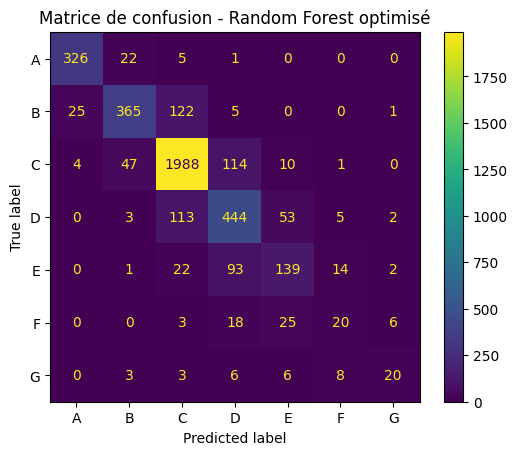

In [44]:
# ------------------------------------------------------------
# Matrice de confusion
# ------------------------------------------------------------

# Importer les outils nécessaires.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


# Calculer la matrice de confusion.
# Les lignes correspondent aux vraies classes.
# Les colonnes correspondent aux classes prédites.
cm = confusion_matrix(
    y_test,
    y_pred_best_rf,
    labels=["A", "B", "C", "D", "E", "F", "G"]
)


# Créer un affichage lisible de la matrice.
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["A", "B", "C", "D", "E", "F", "G"]
)


# Afficher la matrice.
display.plot()

plt.title("Matrice de confusion - Random Forest optimisé")
plt.show()

In [40]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        digits=3
    )
)

              precision    recall  f1-score   support

           A      0.846     0.850     0.848       354
           B      0.722     0.658     0.689       518
           C      0.836     0.904     0.869      2164
           D      0.611     0.626     0.618       620
           E      0.607     0.428     0.502       271
           F      0.515     0.236     0.324        72
           G      0.789     0.326     0.462        46

    accuracy                          0.775      4045
   macro avg      0.704     0.576     0.616      4045
weighted avg      0.766     0.775     0.767      4045



In [47]:
import os
import joblib

os.makedirs("MLmodels", exist_ok=True)

joblib.dump(
    best_rf,
    "MLmodels/pipeline_random_forest_classification_dpe.pkl",
    compress=3
)

print("Modèle de classification DPE sauvegardé.")

Modèle de classification DPE sauvegardé.


In [48]:
joblib.dump(
    {
        "quantitative_features": quantitative_features,
        "qualitative_features": qualitative_features,
        "target": "etiquette_dpe",
    },
    "MLmodels/features_target_columns_classification_dpe.pkl",
)

print("Variables de classification sauvegardées.")

Variables de classification sauvegardées.


In [49]:
import os

print(os.path.exists(
    "MLmodels/pipeline_random_forest_classification_dpe.pkl"
))

print(os.path.exists(
    "MLmodels/features_target_columns_classification_dpe.pkl"
))

True
True


In [50]:
import joblib

modele_dpe = joblib.load(
    "MLmodels/pipeline_random_forest_classification_dpe.pkl"
)

infos_dpe = joblib.load(
    "MLmodels/features_target_columns_classification_dpe.pkl"
)

print(type(modele_dpe))
print(infos_dpe)

<class 'sklearn.pipeline.Pipeline'>
{'quantitative_features': ['cout_total_5_usages', 'surface_habitable_logement', 'nombre_niveau_logement', 'age_batiment', 'altitude_moyenne'], 'qualitative_features': ['type_energie_principale_chauffage', 'type_batiment', 'zone_climatique'], 'target': 'etiquette_dpe'}
